In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares


# ============================================================
# 1. Load JUN18 steady-state data
# ============================================================

file_path = "/mnt/c/Users/sylvi/Desktop/JUN18.xlsx"

raw = pd.read_excel(
    file_path,
    sheet_name="Steady State & SAOS",
    header=None
)


# SS1: first steady-state experiment
ss1 = pd.DataFrame({
    "shear_rate": pd.to_numeric(raw.iloc[2:18, 0], errors="coerce"),
    "stress": pd.to_numeric(raw.iloc[2:18, 1], errors="coerce")
}).dropna()


# SS2: second steady-state experiment
ss2 = pd.DataFrame({
    "shear_rate": pd.to_numeric(raw.iloc[2:18, 4], errors="coerce"),
    "stress": pd.to_numeric(raw.iloc[2:18, 5], errors="coerce")
}).dropna()


print("SS1")
print(ss1)

print("\nSS2")
print(ss2)

SS1
    shear_rate    stress
2         0.10  0.002059
3         0.20  0.004010
4         0.35  0.007133
5         0.70  0.012580
6         1.00  0.015760
7         2.00  0.023760
8         3.50  0.033711
9         7.00  0.051800
10       10.00  0.065400
11       20.00  0.108970
12       35.00  0.168900
13       70.00  0.298000
14      100.00  0.403668
15      200.00  0.720695
16      350.00  1.185800
17      700.00  2.232500

SS2
    shear_rate   stress
2         0.10  0.00330
3         0.20  0.00575
4         0.35  0.01100
5         0.70  0.01848
6         1.00  0.02326
7         2.00  0.03395
8         3.50  0.04629
9         7.00  0.06833
10       10.00  0.08490
11       20.00  0.13600
12       35.00  0.20320
13       70.00  0.34850
14      100.00  0.46330
15      200.00  0.84800
16      350.00  1.41000
17      700.00  2.71000


In [2]:
# ============================================================
# 2. Fixed parameters for human blood
# ============================================================

d = 0.5
m = 1.5


# ============================================================
# 3. Steady-state t-ESSTV model
# ============================================================

def tesstv_steady(
    shear_rate,
    mu_zero,
    mu_inf,
    tau_cross,
    tau_break,
    tau_build,
    mu_rouleaux,
    yield_stress
):
    """
    Calculate steady-state t-ESSTV stress.

    Input:
        shear_rate

    Fitted parameters:
        mu_zero
        mu_inf
        tau_cross
        tau_break
        tau_build
        mu_rouleaux
        yield_stress

    Output:
        predicted total stress
    """

    shear_rate = np.asarray(
        shear_rate,
        dtype=float
    )


    # --------------------------------------------------------
    # Plasma + individual RBC viscosity
    # --------------------------------------------------------

    viscosity = (
        mu_inf
        + (mu_zero - mu_inf)
        / (
            1
            + tau_cross * np.abs(shear_rate)
        )
    )


    # --------------------------------------------------------
    # Rouleaux steady-state structure lambda
    # --------------------------------------------------------

    build_term = (
        np.abs(
            tau_build * shear_rate
        ) ** d
        + 1
    )

    break_term = (
        tau_break
        * np.abs(shear_rate)
    )

    lam = (
        build_term
        / (
            break_term
            + build_term
        )
    )


    # --------------------------------------------------------
    # Stress components
    # --------------------------------------------------------

    cell_stress = (
        viscosity
        * shear_rate
    )

    rouleaux_viscous_stress = (
        mu_rouleaux
        * lam ** m
        * shear_rate
    )

    rouleaux_yield_stress = (
        yield_stress
        * lam
        * np.sign(shear_rate)
    )


    total_stress = (
        cell_stress
        + rouleaux_viscous_stress
        + rouleaux_yield_stress
    )


    return total_stress

In [3]:
# ============================================================
# 4. Residual used by the optimizer
# ============================================================

def steady_residuals(
    params,
    shear_rate,
    measured_stress
):

    predicted_stress = tesstv_steady(
        shear_rate,
        *params
    )


    # Relative residual:
    # prevents high-stress points from dominating everything
    scale = np.maximum(
        np.abs(measured_stress),
        1e-4
    )

    residual = (
        predicted_stress
        - measured_stress
    ) / scale


    return residual

In [4]:
# ============================================================
# 5. Fit one steady-state dataset
# ============================================================

def fit_steady_data(data):

    shear_rate = data[
        "shear_rate"
    ].to_numpy(dtype=float)

    measured_stress = data[
        "stress"
    ].to_numpy(dtype=float)


    # Published Donor 5 values:
    # only used as initial guesses
    initial_guess = [
        0.0138,   # mu_zero
        0.0054,   # mu_inf
        0.029,    # tau_cross
        1.582,    # tau_break
        0.192,    # tau_build
        0.099,    # mu_rouleaux
        0.0039    # yield_stress
    ]


    lower_bounds = [
        1e-4,
        1e-4,
        1e-5,
        1e-4,
        1e-8,
        1e-4,
        0.0
    ]


    upper_bounds = [
        0.1,
        0.1,
        10.0,
        20.0,
        20.0,
        1.0,
        0.1
    ]


    result = least_squares(
        steady_residuals,

        x0=initial_guess,

        bounds=(
            lower_bounds,
            upper_bounds
        ),

        args=(
            shear_rate,
            measured_stress
        ),

        max_nfev=30000
    )


    fitted_params = result.x


    predicted_stress = tesstv_steady(
        shear_rate,
        *fitted_params
    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse = np.sqrt(
        np.mean(
            (
                measured_stress
                - predicted_stress
            ) ** 2
        )
    )


    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    ss_res = np.sum(
        (
            measured_stress
            - predicted_stress
        ) ** 2
    )

    ss_tot = np.sum(
        (
            measured_stress
            - np.mean(measured_stress)
        ) ** 2
    )

    r2 = (
        1
        - ss_res / ss_tot
    )


    return {
        "params": fitted_params,
        "shear_rate": shear_rate,
        "measured": measured_stress,
        "predicted": predicted_stress,
        "rmse": rmse,
        "r2": r2,
        "success": result.success
    }

In [5]:
# ============================================================
# 6. Fit SS1 and SS2
# ============================================================

fit_ss1 = fit_steady_data(ss1)
fit_ss2 = fit_steady_data(ss2)

In [6]:
# ============================================================
# 7. Print fitted parameters
# ============================================================

parameter_names = [
    "mu_zero",
    "mu_inf",
    "tau_cross",
    "tau_break",
    "tau_build",
    "mu_rouleaux",
    "yield_stress"
]


def print_fit(name, fit):

    print(f"\n{name}")
    print("=" * 40)

    for parameter_name, value in zip(
        parameter_names,
        fit["params"]
    ):

        print(
            f"{parameter_name:15s} = {value:.6g}"
        )


    print(
        f"\nRMSE = {fit['rmse']:.6f} Pa"
    )

    print(
        f"R²   = {fit['r2']:.6f}"
    )


print_fit(
    "JUN18 SS1",
    fit_ss1
)

print_fit(
    "JUN18 SS2",
    fit_ss2
)


JUN18 SS1
mu_zero         = 0.0214696
mu_inf          = 0.00294549
tau_cross       = 0.65347
tau_break       = 0.00362184
tau_build       = 1e-08
mu_rouleaux     = 0.00126008
yield_stress    = 4.90627e-51

RMSE = 0.003244 Pa
R²   = 0.999969

JUN18 SS2
mu_zero         = 0.0338508
mu_inf          = 0.00371574
tau_cross       = 0.704221
tau_break       = 0.00682749
tau_build       = 1e-08
mu_rouleaux     = 0.0011766
yield_stress    = 7.75586e-47

RMSE = 0.002339 Pa
R²   = 0.999989


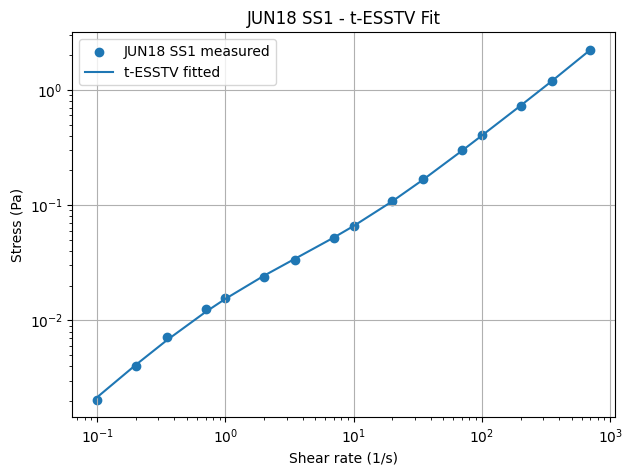

In [7]:
# ============================================================
# 8. Plot SS1 fit
# ============================================================

order = np.argsort(
    fit_ss1["shear_rate"]
)


plt.figure(figsize=(7, 5))

plt.scatter(
    fit_ss1["shear_rate"],
    fit_ss1["measured"],
    label="JUN18 SS1 measured"
)

plt.plot(
    fit_ss1["shear_rate"][order],
    fit_ss1["predicted"][order],
    label="t-ESSTV fitted"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "JUN18 SS1 - t-ESSTV Fit"
)

plt.legend()
plt.grid(True)

plt.show()

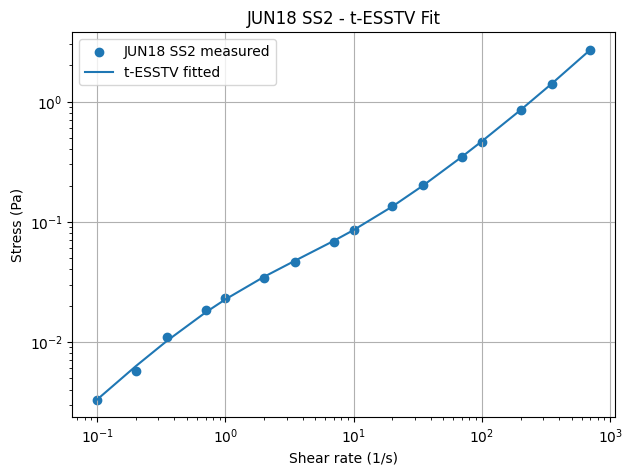

In [8]:
# ============================================================
# 9. Plot SS2 fit
# ============================================================

order = np.argsort(
    fit_ss2["shear_rate"]
)


plt.figure(figsize=(7, 5))

plt.scatter(
    fit_ss2["shear_rate"],
    fit_ss2["measured"],
    label="JUN18 SS2 measured"
)

plt.plot(
    fit_ss2["shear_rate"][order],
    fit_ss2["predicted"][order],
    label="t-ESSTV fitted"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "JUN18 SS2 - t-ESSTV Fit"
)

plt.legend()
plt.grid(True)

plt.show()

### Step Up/Down

Using SS1
    shear_rate    stress
2         0.10  0.002059
3         0.20  0.004010
4         0.35  0.007133
5         0.70  0.012580
6         1.00  0.015760
7         2.00  0.023760
8         3.50  0.033711
9         7.00  0.051800
10       10.00  0.065400
11       20.00  0.108970
12       35.00  0.168900
13       70.00  0.298000
14      100.00  0.403668
15      200.00  0.720695
16      350.00  1.185800
17      700.00  2.232500


SS1 fitted steady-state parameters
mu_zero        = 0.02146961
mu_inf         = 0.00294549
tau_cross      = 0.65347042
tau_break      = 0.00362184
tau_build      = 0.00000001
mu_rouleaux    = 0.00126008
yield_stress   = 0.00000000

SS RMSE = 0.003244 Pa
SS R²   = 0.999969

Transient points: 4186

Fitted transient parameters
tau_structure = 0.32098846 s
G_rouleaux    = 1.47850455 Pa
G_cell        = 0.18806262 Pa

Transient RMSE = 0.004844 Pa
Transient R²   = -1.562745


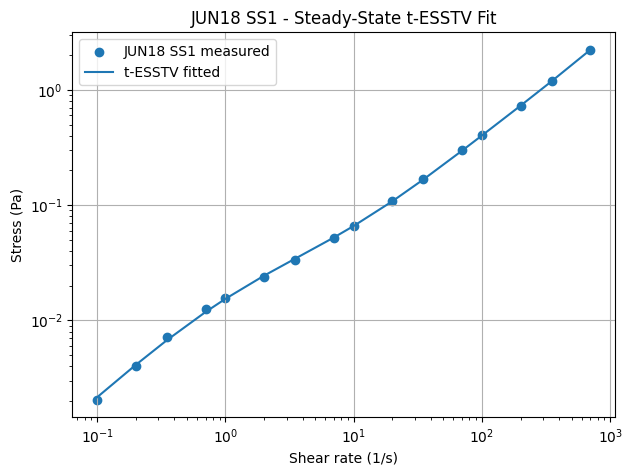

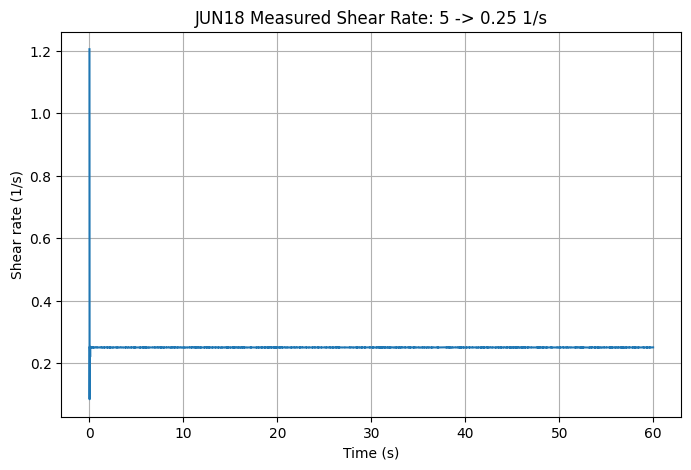

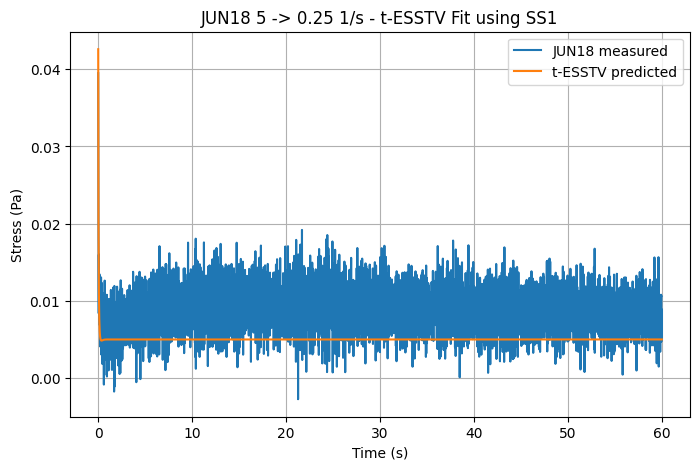

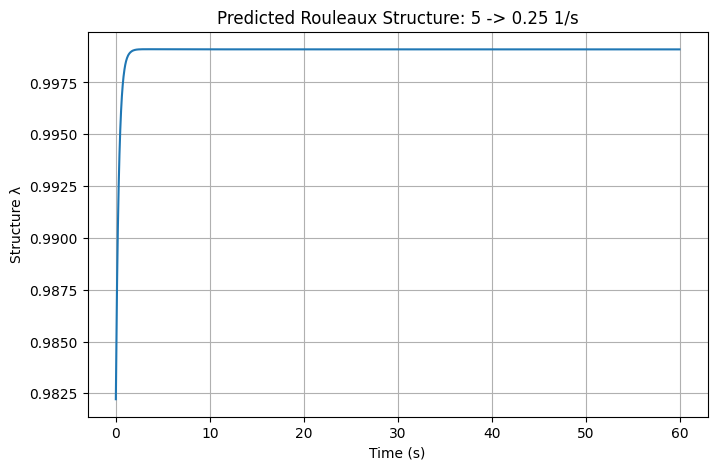

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d


# ============================================================
# USER SETTINGS
# ============================================================

FILE_PATH = "/mnt/c/Users/sylvi/Desktop/JUN18.xlsx"

# Choose which JUN18 steady-state run to use
SS_RUN = "SS1"       # change to "SS2" if needed

# For now, fit this real transient experiment
STEP_NAME = "5_to_0.25"


# ============================================================
# FIXED PARAMETERS FOR HUMAN BLOOD
# ============================================================

d = 0.5
m = 1.5
gamma0_rouleaux = 1.0


# ============================================================
# 1. LOAD JUN18 STEADY-STATE DATA
# ============================================================

raw_ss = pd.read_excel(
    FILE_PATH,
    sheet_name="Steady State & SAOS",
    header=None
)


if SS_RUN == "SS1":

    ss_data = pd.DataFrame({
        "shear_rate":
            pd.to_numeric(
                raw_ss.iloc[2:18, 0],
                errors="coerce"
            ),

        "stress":
            pd.to_numeric(
                raw_ss.iloc[2:18, 1],
                errors="coerce"
            )
    }).dropna()


elif SS_RUN == "SS2":

    ss_data = pd.DataFrame({
        "shear_rate":
            pd.to_numeric(
                raw_ss.iloc[2:18, 4],
                errors="coerce"
            ),

        "stress":
            pd.to_numeric(
                raw_ss.iloc[2:18, 5],
                errors="coerce"
            )
    }).dropna()


else:

    raise ValueError(
        'SS_RUN must be "SS1" or "SS2"'
    )


ss_shear = ss_data[
    "shear_rate"
].to_numpy(dtype=float)

ss_stress = ss_data[
    "stress"
].to_numpy(dtype=float)


print(f"Using {SS_RUN}")
print(ss_data)


# ============================================================
# 2. STEADY-STATE t-ESSTV MODEL
# ============================================================

def steady_model(
    shear_rate,
    mu_zero,
    mu_inf,
    tau_cross,
    tau_break,
    tau_build,
    mu_rouleaux,
    yield_stress
):

    """
    Steady-state t-ESSTV total stress.
    """

    shear_rate = np.asarray(
        shear_rate,
        dtype=float
    )


    # Plasma + individual RBC viscosity
    viscosity = (
        mu_inf
        + (mu_zero - mu_inf)
        / (
            1
            + tau_cross
            * np.abs(shear_rate)
        )
    )


    # Steady-state rouleaux structure
    build_term = (
        np.abs(
            tau_build * shear_rate
        ) ** d
        + 1
    )

    break_term = (
        tau_break
        * np.abs(shear_rate)
    )

    lam = (
        build_term
        / (
            build_term
            + break_term
        )
    )


    # Plasma / RBC stress
    cell_stress = (
        viscosity
        * shear_rate
    )


    # Rouleaux viscous stress
    rouleaux_viscous_stress = (
        mu_rouleaux
        * lam ** m
        * shear_rate
    )


    # Rouleaux yield stress
    rouleaux_yield_stress = (
        yield_stress
        * lam
        * np.sign(shear_rate)
    )


    total_stress = (
        cell_stress
        + rouleaux_viscous_stress
        + rouleaux_yield_stress
    )


    return total_stress


# ============================================================
# 3. FIT STEADY-STATE PARAMETERS
# ============================================================

def steady_residuals(
    params
):

    predicted = steady_model(
        ss_shear,
        *params
    )


    # Relative error
    scale = np.maximum(
        np.abs(ss_stress),
        1e-4
    )


    return (
        predicted
        - ss_stress
    ) / scale


# Donor 5 values used ONLY as starting guesses
steady_initial_guess = [
    0.0138,   # mu_zero
    0.0054,   # mu_inf
    0.029,    # tau_cross
    1.582,    # tau_break
    0.192,    # tau_build
    0.099,    # mu_rouleaux
    0.0039    # yield_stress
]


steady_lower_bounds = [
    1e-4,
    1e-4,
    1e-5,
    1e-4,
    1e-8,
    1e-4,
    0.0
]


steady_upper_bounds = [
    0.1,
    0.1,
    10.0,
    20.0,
    20.0,
    1.0,
    0.1
]


steady_fit = least_squares(

    steady_residuals,

    x0=steady_initial_guess,

    bounds=(
        steady_lower_bounds,
        steady_upper_bounds
    ),

    max_nfev=30000
)


(
    mu_zero,
    mu_inf,
    tau_cross,
    tau_break,
    tau_build,
    mu_rouleaux,
    yield_stress
) = steady_fit.x


ss_predicted = steady_model(
    ss_shear,
    *steady_fit.x
)


# ============================================================
# 4. STEADY-STATE FIT METRICS
# ============================================================

ss_rmse = np.sqrt(
    np.mean(
        (
            ss_stress
            - ss_predicted
        ) ** 2
    )
)


ss_res = np.sum(
    (
        ss_stress
        - ss_predicted
    ) ** 2
)


ss_tot = np.sum(
    (
        ss_stress
        - np.mean(ss_stress)
    ) ** 2
)


ss_r2 = (
    1
    - ss_res / ss_tot
)


print("\n")
print(
    f"{SS_RUN} fitted steady-state parameters"
)
print("=" * 45)

print(f"mu_zero        = {mu_zero:.8f}")
print(f"mu_inf         = {mu_inf:.8f}")
print(f"tau_cross      = {tau_cross:.8f}")
print(f"tau_break      = {tau_break:.8f}")
print(f"tau_build      = {tau_build:.8f}")
print(f"mu_rouleaux    = {mu_rouleaux:.8f}")
print(f"yield_stress   = {yield_stress:.8f}")

print()
print(f"SS RMSE = {ss_rmse:.6f} Pa")
print(f"SS R²   = {ss_r2:.6f}")


# ============================================================
# 5. LOAD REAL JUN18 STEP-DOWN DATA
#
# JUN18 Excel:
# columns 15-18 = 5 -> 0.25 1/s
# time | stress | strain | shear rate
# ============================================================

raw_step = pd.read_excel(
    FILE_PATH,
    sheet_name="Step Up Step Down",
    header=None
)


if STEP_NAME == "5_to_0.25":

    initial_shear = 5.0

    step_data = pd.DataFrame({

        "time":
            pd.to_numeric(
                raw_step.iloc[3:, 15],
                errors="coerce"
            ),

        "stress":
            pd.to_numeric(
                raw_step.iloc[3:, 16],
                errors="coerce"
            ),

        "shear_rate":
            pd.to_numeric(
                raw_step.iloc[3:, 18],
                errors="coerce"
            )

    }).dropna()


else:

    raise ValueError(
        "Only 5_to_0.25 is configured in this version."
    )


# Make experimental time start at zero
step_data["time"] = (
    step_data["time"]
    - step_data["time"].iloc[0]
)


time_data = step_data[
    "time"
].to_numpy(dtype=float)

stress_data = step_data[
    "stress"
].to_numpy(dtype=float)

shear_data = step_data[
    "shear_rate"
].to_numpy(dtype=float)


print()
print(
    f"Transient points: {len(step_data)}"
)


# ============================================================
# 6. REAL MEASURED SHEAR-RATE FUNCTION
#
# The rheometer does not produce a mathematically perfect step.
# Therefore use the measured shear-rate history.
# ============================================================

shear_function = interp1d(

    time_data,
    shear_data,

    kind="linear",

    bounds_error=False,

    # Before the first recorded point,
    # assume the sample was at 5 1/s.
    fill_value=(
        initial_shear,
        shear_data[-1]
    )
)


# ============================================================
# 7. HELPER FUNCTIONS
# ============================================================

def cross_viscosity(
    shear_rate
):

    """
    Steady plasma/RBC viscosity.
    """

    return (
        mu_inf
        + (mu_zero - mu_inf)
        / (
            1
            + tau_cross
            * abs(shear_rate)
        )
    )


def steady_structure(
    shear_rate
):

    """
    Steady-state rouleaux structure lambda.
    """

    build_term = (
        abs(
            tau_build
            * shear_rate
        ) ** d
        + 1
    )

    break_term = (
        tau_break
        * abs(shear_rate)
    )


    return (
        build_term
        / (
            build_term
            + break_term
        )
    )


def transient_viscosity(
    normal_stress,
    G_cell
):

    """
    Plasma/RBC transient viscosity
    from the White-Metzner auxiliary equation.
    """

    normal_stress = max(
        normal_stress,
        0.0
    )


    root_term = np.sqrt(
        G_cell
        * normal_stress
        / 2
    )


    b = (
        tau_cross
        * root_term
        - mu_zero
    )


    c = (
        -mu_inf
        * tau_cross
        * root_term
    )


    discriminant = (
        b ** 2
        - 4 * c
    )


    discriminant = max(
        discriminant,
        1e-18
    )


    viscosity = (
        -b
        + np.sqrt(discriminant)
    ) / 2


    return max(
        viscosity,
        1e-8
    )


# ============================================================
# 8. INITIAL STATE
#
# Important:
# the first recorded shear-rate point is NOT 5 1/s.
#
# The step has already begun by the time the first recorded
# point appears, so initialise the model from 5 1/s,
# based on the experiment itself.
# ============================================================

def initial_state(
    initial_shear,
    G_cell
):

    lam = steady_structure(
        initial_shear
    )


    elastic_strain = (
        gamma0_rouleaux
        * lam
        * np.sign(initial_shear)
    )


    viscosity = cross_viscosity(
        initial_shear
    )


    cell_shear_stress = (
        viscosity
        * initial_shear
    )


    cell_normal_stress = (
        2
        * viscosity ** 2
        * initial_shear ** 2
        / G_cell
    )


    rouleaux_stress = (
        mu_rouleaux
        * lam ** m
        * initial_shear

        + yield_stress
        * lam
        * np.sign(initial_shear)
    )


    return [
        lam,
        elastic_strain,
        cell_shear_stress,
        cell_normal_stress,
        rouleaux_stress
    ]


# ============================================================
# 9. NON-TENSORIAL TRANSIENT t-ESSTV ODE
# ============================================================

def transient_equations(
    time,
    state,
    tau_structure,
    G_rouleaux,
    G_cell
):

    (
        lam,
        elastic_strain,
        cell_shear_stress,
        cell_normal_stress,
        rouleaux_stress
    ) = state


    # Real experimental shear rate at this time
    shear_rate = float(
        shear_function(time)
    )


    # Keep lambda numerically safe
    lam_safe = np.clip(
        lam,
        1e-6,
        1.0
    )


    # Maximum elastic strain
    max_elastic_strain = (
        gamma0_rouleaux
        * lam_safe
    )


    max_elastic_strain = max(
        max_elastic_strain,
        1e-6
    )


    # --------------------------------------------------------
    # Plastic shear rate
    # --------------------------------------------------------

    denominator = (
        2
        - elastic_strain
        / max_elastic_strain
    )


    if abs(denominator) < 1e-6:

        denominator = (
            1e-6
            if denominator >= 0
            else -1e-6
        )


    plastic_shear_rate = (
        shear_rate
        / denominator
    )


    # --------------------------------------------------------
    # Rouleaux structure evolution
    # --------------------------------------------------------

    breakdown = (
        tau_break
        * abs(plastic_shear_rate)
        * lam_safe
    )


    buildup = (
        (1 - lam_safe)
        * (
            abs(
                tau_build
                * plastic_shear_rate
            ) ** d
            + 1
        )
    )


    d_lambda = (
        buildup
        - breakdown
    ) / tau_structure


    # --------------------------------------------------------
    # Elastic strain evolution
    # --------------------------------------------------------

    d_max_elastic_strain = (
        gamma0_rouleaux
        * d_lambda
    )


    d_elastic_strain = (

        plastic_shear_rate

        - (
            elastic_strain
            / max_elastic_strain
        )
        * abs(plastic_shear_rate)

    )


    if d_max_elastic_strain < 0:

        d_elastic_strain += (
            elastic_strain
            / max_elastic_strain
        ) * d_max_elastic_strain


    # --------------------------------------------------------
    # Plasma / individual RBC contribution
    # --------------------------------------------------------

    viscosity = transient_viscosity(
        cell_normal_stress,
        G_cell
    )


    d_cell_shear_stress = (
        G_cell
        * (
            shear_rate
            - cell_shear_stress
            / viscosity
        )
    )


    d_cell_normal_stress = (

        2
        * shear_rate
        * cell_shear_stress

        - G_cell
        * cell_normal_stress
        / viscosity

    )


    # --------------------------------------------------------
    # Rouleaux EVP stress contribution
    # --------------------------------------------------------

    structure_viscosity = (
        lam_safe ** m
        * mu_rouleaux
    )


    structure_viscosity = max(
        structure_viscosity,
        1e-8
    )


    yield_part = (
        yield_stress
        / gamma0_rouleaux
        * elastic_strain
    )


    stress_difference = (
        rouleaux_stress
        - yield_part
    )


    if abs(rouleaux_stress) > 1e-10:

        stress_direction = np.sign(
            rouleaux_stress
        )

    else:

        stress_direction = np.sign(
            shear_rate
        )


    plastic_flow = (

        abs(stress_difference)
        / structure_viscosity

        * stress_direction

    )


    d_rouleaux_stress = (

        lam_safe
        * G_rouleaux

        * (
            shear_rate
            - plastic_flow
        )

    )


    return [
        d_lambda,
        d_elastic_strain,
        d_cell_shear_stress,
        d_cell_normal_stress,
        d_rouleaux_stress
    ]


# ============================================================
# 10. RUN TRANSIENT MODEL
# ============================================================

def run_transient(
    transient_params,
    output_times
):

    tau_structure = transient_params[0]
    G_rouleaux = transient_params[1]
    G_cell = transient_params[2]


    start_state = initial_state(
        initial_shear,
        G_cell
    )


    solution = solve_ivp(

        fun=lambda t, y:
            transient_equations(
                t,
                y,
                tau_structure,
                G_rouleaux,
                G_cell
            ),

        t_span=(
            time_data[0],
            time_data[-1]
        ),

        y0=start_state,

        t_eval=output_times,

        method="BDF",

        rtol=1e-5,
        atol=1e-7
    )


    if not solution.success:

        return None


    cell_stress = (
        solution.y[2]
    )


    rouleaux_stress = (
        solution.y[4]
    )


    total_stress = (
        cell_stress
        + rouleaux_stress
    )


    return {
        "solution": solution,
        "total_stress": total_stress
    }


# ============================================================
# 11. FIT TRANSIENT PARAMETERS
#
# Fit:
#     tau_structure = tau_lambda
#     G_rouleaux     = G_R
#     G_cell         = G_C
#
# Steady parameters above come from JUN18 SS1 / SS2.
# ============================================================


# Use fewer points while fitting to make optimisation faster.
# Keep dense data near the start because the transient occurs there.

early_points = np.arange(
    0,
    min(200, len(time_data))
)

later_points = np.arange(
    200,
    len(time_data),
    20
)

fit_indices = np.unique(
    np.concatenate([
        early_points,
        later_points,
        [len(time_data) - 1]
    ])
)


fit_times = (
    time_data[fit_indices]
)

fit_stress = (
    stress_data[fit_indices]
)


# Normalise transient residual by maximum measured stress,
# similar to the fitting logic used in the paper.
stress_scale = max(
    np.max(
        np.abs(fit_stress)
    ),
    1e-4
)


def transient_residuals(
    params
):

    result = run_transient(
        params,
        fit_times
    )


    if result is None:

        return np.full(
            len(fit_times),
            1e6
        )


    predicted = result[
        "total_stress"
    ]


    if np.any(
        ~np.isfinite(predicted)
    ):

        return np.full(
            len(fit_times),
            1e6
        )


    return (
        predicted
        - fit_stress
    ) / stress_scale


# Published values are only INITIAL GUESSES here
transient_initial_guess = [
    1.4582,   # tau_structure
    0.2646,   # G_rouleaux
    0.5138    # G_cell
]


transient_lower_bounds = [
    0.01,
    0.001,
    0.01
]


transient_upper_bounds = [
    20.0,
    5.0,
    5.0
]


transient_fit = least_squares(

    transient_residuals,

    x0=transient_initial_guess,

    bounds=(
        transient_lower_bounds,
        transient_upper_bounds
    ),

    # Larger finite-difference step helps because
    # the ODE solution itself has numerical tolerance.
    diff_step=0.05,

    max_nfev=200
)


tau_structure_fit = (
    transient_fit.x[0]
)

G_rouleaux_fit = (
    transient_fit.x[1]
)

G_cell_fit = (
    transient_fit.x[2]
)


print()
print("Fitted transient parameters")
print("=" * 45)

print(
    f"tau_structure = {tau_structure_fit:.8f} s"
)

print(
    f"G_rouleaux    = {G_rouleaux_fit:.8f} Pa"
)

print(
    f"G_cell        = {G_cell_fit:.8f} Pa"
)


# ============================================================
# 12. FINAL PREDICTION ON ALL JUN18 TRANSIENT POINTS
# ============================================================

final_result = run_transient(

    [
        tau_structure_fit,
        G_rouleaux_fit,
        G_cell_fit
    ],

    time_data
)


if final_result is None:

    raise RuntimeError(
        "Final transient solver failed."
    )


solution = final_result[
    "solution"
]


stress_predicted = final_result[
    "total_stress"
]


lambda_predicted = (
    solution.y[0]
)


# ============================================================
# 13. TRANSIENT FIT METRICS
# ============================================================

transient_rmse = np.sqrt(

    np.mean(
        (
            stress_data
            - stress_predicted
        ) ** 2
    )

)


transient_ss_res = np.sum(
    (
        stress_data
        - stress_predicted
    ) ** 2
)


transient_ss_tot = np.sum(
    (
        stress_data
        - np.mean(stress_data)
    ) ** 2
)


transient_r2 = (
    1
    - transient_ss_res
    / transient_ss_tot
)


print()
print(
    f"Transient RMSE = {transient_rmse:.6f} Pa"
)

print(
    f"Transient R²   = {transient_r2:.6f}"
)


# ============================================================
# 14. PLOT: STEADY-STATE FIT
# ============================================================

order = np.argsort(
    ss_shear
)


plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    ss_shear,
    ss_stress,
    label=f"JUN18 {SS_RUN} measured"
)

plt.plot(
    ss_shear[order],
    ss_predicted[order],
    label="t-ESSTV fitted"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    "Shear rate (1/s)"
)

plt.ylabel(
    "Stress (Pa)"
)

plt.title(
    f"JUN18 {SS_RUN} - Steady-State t-ESSTV Fit"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 15. PLOT: REAL SHEAR-RATE INPUT
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    time_data,
    shear_data
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Shear rate (1/s)"
)

plt.title(
    "JUN18 Measured Shear Rate: 5 -> 0.25 1/s"
)

plt.grid(True)

plt.show()


# ============================================================
# 16. PLOT: MEASURED VS PREDICTED TRANSIENT STRESS
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    time_data,
    stress_data,
    label="JUN18 measured"
)

plt.plot(
    time_data,
    stress_predicted,
    label="t-ESSTV predicted"
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Stress (Pa)"
)

plt.title(
    f"JUN18 5 -> 0.25 1/s - t-ESSTV Fit using {SS_RUN}"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 17. PLOT: PREDICTED ROULEAUX STRUCTURE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    time_data,
    lambda_predicted
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Structure λ"
)

plt.title(
    "Predicted Rouleaux Structure: 5 -> 0.25 1/s"
)

plt.grid(True)

plt.show()